# Trees, traversals, BFS & DFS



Work top to bottom. Complete each task before running its check. Edit the trace tables directly.
No extra packages are needed.

## 1. Build a tree
A binary-tree node has a value and at most two children. `None` means no child.
Run this three-node example.

In [1]:
class Node:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right


a = Node("X")
a.left = Node("Y")
a.right = Node("Z")

print(a.value, a.left.value, a.right.value)

X Y Z


Build this tree as `root`. Create and connect each node yourself. L = left; R = right.

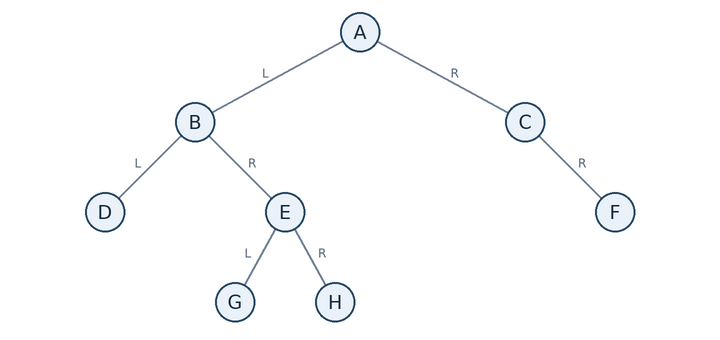

In [4]:
root = None
# TODO: create and connect all eight nodes.

In [6]:
# 1. Build the tree structure from the bottom up
d = Node("D")
g = Node("G")
h = Node("H")
f = Node("F")

e = Node("E", left=g, right=h)
b = Node("B", left=d, right=e)
c = Node("C", left=None, right=f)  # root.right.left is explicitly None

root = Node("A", left=b, right=c)

In [7]:
assert isinstance(root, Node), "Build root first."
_nodes = [root, root.left, root.right, root.left.left, root.left.right,
          root.right.right, root.left.right.left, root.left.right.right]
assert all(isinstance(n, Node) for n in _nodes)
assert [n.value for n in _nodes] == list("ABCDEFGH")
assert len({id(n) for n in _nodes}) == 8
assert root.right.left is None
assert all(n.left is None and n.right is None for n in
           [root.left.left, root.right.right, root.left.right.left, root.left.right.right])
print("Tree check passed.")

Tree check passed.


## 2. Read and change links
1. Read the labels of G's parent and E's sibling through `root`.
2. Write the root-to-H path as a list of labels.
3. Add I as D's right child, read its label into `added_value`, then remove I.

Continue with the original eight-node tree.

In [16]:
parent_of_g = root.left.right.value
sibling_of_e = root.left.left.value
path_to_h = ['A', 'B', 'E', 'H']

# TODO: attach I.
root.left.left.right = Node("I")
added_value = root.left.left.right.value
# TODO: remove I again.
root.left.left.right = None

In [17]:
assert parent_of_g == "E"
assert sibling_of_e == "D"
assert path_to_h == ["A", "B", "E", "H"]
assert added_value == "I"
assert root.left.left.value == "D" and root.left.left.right is None
print("Link checks passed.")

Link checks passed.


## 3. Predict the traversals
Apply each rule to every subtree. Write the label sequence **before coding**.

| Traversal | Visit order |
|---|---|
| Postorder | Left subtree → right subtree → node |
| Inorder | Left subtree → node → right subtree |
| Preorder | Node → left subtree → right subtree |

In [ ]:
post_by_hand = ['D', 'G', 'H', 'E', 'B', 'F', 'C', 'A']
in_by_hand = ['D', 'B', 'G', 'E', 'H', 'A', 'C', 'F']
pre_by_hand = ['A', 'B', 'D', 'E', 'G', 'H', 'C', 'F']

In [27]:
# Define hand-calculated expected sequences
post_by_hand = ["D", "G", "H", "E", "B", "F", "C", "A"]
in_by_hand = ["D", "B", "G", "E", "H", "A", "C", "F"]
pre_by_hand = ["A", "B", "D", "E", "G", "H", "C", "F"]

# Map function names if they differ from your earlier definitions
#postorder = postorder
#inorder = inorder
#preorder = preorder

## 4. Implement the traversals
Return a list of labels. For an empty tree, return `[]`. Leave the tree unchanged.

In [28]:
def inorder(node):
  if node is None:
    return []
  return (
      inorder(node.left) + [node.value] + inorder(node.right)
  )

In [29]:

def postorder(node):
  if node is None:
    return []
  return (
      postorder(node.left)
      + postorder(node.right)
      + [node.value]
  )

In [30]:
def preorder(node):
  if node is None:
    return []
  return (
      [node.value] + preorder(node.left) + preorder(node.right)
  )

In [31]:
_before = [(n.value, n.left, n.right) for n in _nodes]
_cases = [
    (postorder, post_by_hand, ["D", "G", "H", "E", "B", "F", "C", "A"], ["Y", "X"]),
    (inorder, in_by_hand, ["D", "B", "G", "E", "H", "A", "C", "F"], ["X", "Y"]),
    (preorder, pre_by_hand, ["A", "B", "D", "E", "G", "H", "C", "F"], ["X", "Y"]),
]
for fn, prediction, expected, right_only in _cases:
    assert prediction == expected, f"Recheck your {fn.__name__} prediction."
    assert fn(root) == expected, fn.__name__
    assert fn(None) == [], f"{fn.__name__}: empty tree"
    assert fn(Node("X")) == ["X"], f"{fn.__name__}: single node"
    assert fn(Node("X", right=Node("Y"))) == right_only, f"{fn.__name__}: right child only"
assert [(n.value, n.left, n.right) for n in _nodes] == _before, "Keep the tree unchanged."
print("Traversal checks passed.")

Traversal checks passed.


## 5. Trace BFS and DFS
Use the original tree; visit left children first. Complete one row per visit.

**BFS:** visit level by level. Pending nodes form a queue; next is on the **left**.

| Step | Visit | Pending after this step |
|---|---|---|
| 0 | — | A |
| 1 | A | B, C |
| 2 | ___ | ___ |
| 3 | ___ | ___ |
| 4 | ___ | ___ |
| 5 | ___ | ___ |
| 6 | ___ | ___ |
| 7 | ___ | ___ |
| 8 | ___ | ___ |

**DFS:** follow a branch, then backtrack. Use a stack of pending nodes; next is on the **right**.

| Step | Visit | Pending after this step |
|---|---|---|
| 0 | — | A |
| 1 | A | C, B |
| 2 | ___ | ___ |
| 3 | ___ | ___ |
| 4 | ___ | ___ |
| 5 | ___ | ___ |
| 6 | ___ | ___ |
| 7 | ___ | ___ |
| 8 | ___ | ___ |

Copy the visit columns below. Which earlier traversal matches this DFS?

In [36]:
bfs_by_hand = ["A", "B", "C", "D", "E", "F", "G", "H"]
dfs_by_hand = ["A", "B", "D", "E", "G", "H", "C", "F"]
matching_traversal = "preorder"

In [37]:
assert bfs_by_hand == ["A", "B", "C", "D", "E", "F", "G", "H"]
assert dfs_by_hand == pre_by_hand
assert matching_traversal.strip().lower() == "preorder"
print("Visit orders checked. Review the pending columns separately.")

Visit orders checked. Review the pending columns separately.


## 6. Independent task: BFS and DFS
An adjacency list maps each vertex to its neighbours. This undirected graph contains a cycle and an isolated vertex.

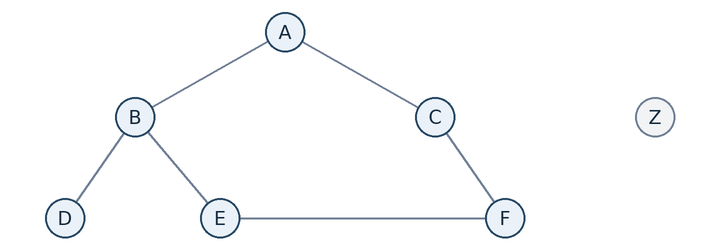

Implement `bfs(graph, start)` and `dfs(graph, start)` from scratch.

- Return reachable vertices in visit order, each once.
- Follow neighbour-list order. DFS must finish an earlier neighbour's branch before a later one.
- Return `[]` for an empty graph or a missing start. Leave the graph unchanged.

Every neighbour is also a dictionary key. No implementation hints are provided.

In [41]:
graph = {
    "A": ["B", "C"],
    "B": ["A", "D", "E"],
    "C": ["A", "F"],
    "D": ["B"],
    "E": ["B", "F"],
    "F": ["C", "E"],
    "Z": [],
}

In [46]:
from collections import deque

In [47]:
def bfs(graph, start):
  """Performs a Breadth-First Search on a graph starting from 'start'.

  Returns a list of reachable vertices in visit order, each once.
  """
  if not graph or start not in graph:
    return []

  visited = []
  seen = {start}
  queue = deque([start])

  while queue:
    node = queue.popleft()
    visited.append(node)

    for neighbor in graph[node]:
      if neighbor not in seen:
        seen.add(neighbor)
        queue.append(neighbor)

  return visited

In [48]:
def dfs(graph, start):
  """Performs a Depth-First Search on a graph starting from 'start'.

  Returns a list of reachable vertices in visit order, each once.
  """
  if not graph or start not in graph:
    return []

  visited = []
  seen = set()
  stack = [start]

  while stack:
    node = stack.pop()
    if node not in seen:
      seen.add(node)
      visited.append(node)
      # Push neighbors in reverse order so the first neighbor
      # in the list is popped and visited first.
      for neighbor in reversed(graph[node]):
        if neighbor not in seen:
          stack.append(neighbor)

  return visited

In [49]:
_saved = {v: neighbours[:] for v, neighbours in graph.items()}
assert bfs(graph, "A") == ["A", "B", "C", "D", "E", "F"]
assert dfs(graph, "A") == ["A", "B", "D", "E", "F", "C"]
assert bfs(graph, "C") == ["C", "A", "F", "B", "E", "D"]
assert dfs(graph, "C") == ["C", "A", "B", "D", "E", "F"]
for fn in (bfs, dfs):
    assert fn(graph, "Z") == ["Z"], f"{fn.__name__}: isolated vertex"
    assert fn({}, "A") == [], f"{fn.__name__}: empty graph"
    assert fn(graph, "missing") == [], f"{fn.__name__}: missing start"
    assert fn({"X": ["X"]}, "X") == ["X"], f"{fn.__name__}: self-loop"
assert graph == _saved, "Keep the graph unchanged."
print("BFS and DFS checks passed.")

BFS and DFS checks passed.


Add two tests of your own.

In [44]:
# Your tests